# MSPE 49600 Project 4: Fluent Simulations and Gaussian Process Modeling

**Student:** Philip Allen  
**Course:** MSPE 49600 – Data Analytics for Motorsports  
**Semester:** Fall 2026

## Objective

Use a 2D NACA 0012 rear-wing section and the completed Fluent force sweep to:

1. build separate Gaussian Process (GP) models for drag and lift,
2. validate those surrogates on held-out CFD runs,
3. quantify predictive uncertainty,
4. evaluate drag per unit of downforce, and
5. recommend one follow-up Fluent simulation.

## CFD setup represented by the supplied project files

- NACA 0012 profile
- chord = 0.300 m
- 201 points per side
- rotation about the quarter-chord point `(0.075, 0, 0)` m
- 50 m/s velocity inlet in +x
- 0 Pa gauge pressure outlet
- top and bottom symmetry boundaries
- no-slip airfoil wall
- drag reported in +x and lift in +y

### Updated-data provenance

The updated Excel workbook supplied for this rebuild contains **9 of the 10 seeded LHS cases**. The missing seeded angle, **6.738699054°**, was then supplied separately from the completed Fluent results in the same `(angle_deg, drag_N, lift_N)` format:

- angle = **6.738699054°**
- drag = **23.182230 N**
- lift = **−1116.603600 N**

Those values are used as the tenth CFD observation. No force value is interpolated or model-generated. The final analysis therefore uses the complete 10-run seeded LHS sweep required by the assignment.


## Task I – Ansys Modeling and Project Setup

The supplied geometry generator creates the NACA 0012 coordinates used by DesignModeler. The supplied Workbench helper connects to the open Workbench server, creates a design point, changes the CAD rotation angle, updates the model, reads the angle/drag/lift parameters, and appends the result to `airfoil_results.csv`.

The sweep required by the assignment is a seeded one-dimensional Latin hypercube with 10 angles over 0–20° using `rng=123`:

```python
sampler = qmc.LatinHypercube(d=1, rng=123)
sample = sampler.random(n=10)
airfoil_angles_deg = qmc.scale(sample, [0.0], [20.0]).ravel()
```

The repository version of `run_airfoil_sweep.py` uses `n=10`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from sklearn.metrics import mean_squared_error

pd.set_option("display.precision", 6)
plt.rcParams["figure.figsize"] = (9, 5)

source = Path("airfoil_results.csv")
df = pd.read_csv(source)

print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("Duplicate angles:", int(df["angle_deg"].duplicated().sum()))
print("Missing values:", int(df.isna().sum().sum()))
print("All forces finite:", bool(np.isfinite(df[["drag_N", "lift_N"]].to_numpy()).all()))
print("Angle range: {:.6f} to {:.6f} deg".format(df.angle_deg.min(), df.angle_deg.max()))
df

Rows: 10
Columns: ['angle_deg', 'drag_N', 'lift_N']
Duplicate angles: 0
Missing values: 0
All forces finite: True
Angle range: 0.491722 to 18.413327 deg


,angle_deg,drag_N,lift_N
0,9.612698,31.665475,-1535.78700
1,0.491722,16.038341,-103.48056
2,5.447419,20.165199,-915.35218
3,3.688284,18.027908,-639.51426
4,17.764431,294.095780,-1283.85310
5,18.413327,284.035660,-1401.69440
6,11.647023,42.258940,-1761.45170
7,15.333088,114.281360,-1745.32540
8,12.022133,43.995801,-1812.24650
9,6.738699,23.182230,-1116.60360


The analysis uses one result at each of the 10 seeded angles. Drag is positive in +x. Lift is signed in +y, so **negative lift corresponds to aerodynamic downforce**.

## Task II – Gaussian Process Modeling and Validation

### Step 9 – Downforce and drag-to-downforce ratio

Downforce is defined as:

\[
D_f = -L
\]

and the efficiency metric is:

\[
rac{D}{D_f} = rac{D}{-L}
\]

I use a **500 N minimum positive downforce** before reporting the ratio. This prevents the very-low-load case near zero angle from appearing artificially attractive simply because both forces are small. All force values are still retained for GP modeling.

In [2]:
MIN_DOWNFORCE_N = 500.0

df = df.sort_values("angle_deg").reset_index(drop=True)
df["downforce_N"] = -df["lift_N"]
df["drag_to_downforce"] = np.where(
    df["downforce_N"] >= MIN_DOWNFORCE_N,
    df["drag_N"] / df["downforce_N"],
    np.nan,
)

cfd_out = df[["angle_deg", "drag_N", "lift_N", "drag_to_downforce"]].copy()
cfd_out.to_csv("philipallen04_pr04_cfd.csv", index=False)
cfd_out

,angle_deg,drag_N,lift_N,drag_to_downforce
0,0.491722,16.038341,-103.48056,NaN
1,3.688284,18.027908,-639.51426,0.028190
2,5.447419,20.165199,-915.35218,0.022030
3,6.738699,23.182230,-1116.60360,0.020761
4,9.612698,31.665475,-1535.78700,0.020618
5,11.647023,42.258940,-1761.45170,0.023991
6,12.022133,43.995801,-1812.24650,0.024277
7,15.333088,114.281360,-1745.32540,0.065479
8,17.764431,294.095780,-1283.85310,0.229073
9,18.413327,284.035660,-1401.69440,0.202637


### Steps 10–11 – Hold-out split and GP fitting

After sorting by angle, the **3rd, 6th, and 9th** runs are reserved for testing, exactly as required. The other seven runs train both GPs.

Each model uses:

```python
GaussianProcessRegressor(
    kernel=ConstantKernel() * RBF(),
    normalize_y=True
)
```

The default scikit-learn optimizer is used.

In [3]:
test_rows = [2, 5, 8]
test = df.iloc[test_rows].copy()
train = df.drop(index=test_rows).copy()

X_train = train[["angle_deg"]].to_numpy()
X_test = test[["angle_deg"]].to_numpy()

def make_gp():
    return GaussianProcessRegressor(
        kernel=ConstantKernel() * RBF(),
        normalize_y=True,
    )

gp_drag = make_gp()
gp_lift = make_gp()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gp_drag.fit(X_train, train["drag_N"].to_numpy())
    gp_lift.fit(X_train, train["lift_N"].to_numpy())

for name, model in [("Drag", gp_drag), ("Lift", gp_lift)]:
    print(name)
    print("  Fitted kernel:", model.kernel_)
    print("  Kernel variance:", model.kernel_.k1.constant_value)
    print("  Length scale (deg):", model.kernel_.k2.length_scale)

Drag
  Fitted kernel: 3.26**2 * RBF(length_scale=7.47)
  Kernel variance: 10.607302348731002
  Length scale (deg): 7.471829154293787
Lift
  Fitted kernel: 1.12**2 * RBF(length_scale=5.28)
  Kernel variance: 1.263154295007281
  Length scale (deg): 5.280841123537937


### Steps 12–14 – Held-out predictions, residuals, RMSE, and validation plots

Residuals are defined as:

\[
e = y_{observed} - y_{predicted}
\]

Separate RMSE values are reported for drag and lift.

In [4]:
drag_pred = gp_drag.predict(X_test)
lift_pred = gp_lift.predict(X_test)

test["pred_drag_N"] = drag_pred
test["pred_lift_N"] = lift_pred
test["drag_residual_N"] = test["drag_N"] - test["pred_drag_N"]
test["lift_residual_N"] = test["lift_N"] - test["pred_lift_N"]

drag_rmse = mean_squared_error(test["drag_N"], test["pred_drag_N"]) ** 0.5
lift_rmse = mean_squared_error(test["lift_N"], test["pred_lift_N"]) ** 0.5

test_table = test[
    [
        "angle_deg",
        "drag_N",
        "pred_drag_N",
        "drag_residual_N",
        "lift_N",
        "pred_lift_N",
        "lift_residual_N",
    ]
].copy()

print(f"Drag test RMSE: {drag_rmse:.6f} N")
print(f"Lift test RMSE: {lift_rmse:.6f} N")
test_table

Drag test RMSE: 31.127057 N
Lift test RMSE: 106.449846 N


,angle_deg,drag_N,pred_drag_N,drag_residual_N,lift_N,pred_lift_N,lift_residual_N
2,5.447419,20.165199,20.086822,0.078377,-915.35218,-926.331158,10.978978
5,11.647023,42.258940,41.013486,1.245454,-1761.45170,-1782.755678,21.303978
8,17.764431,294.095780,240.196580,53.899200,-1283.85310,-1466.665331,182.812231


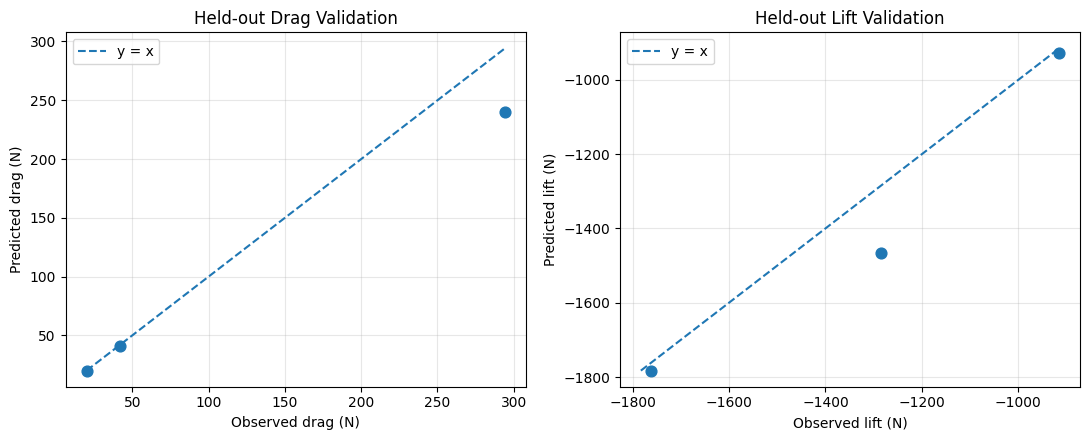

Largest absolute drag error: 53.899 N at 17.764 deg
Largest absolute lift error: 182.812 N at 17.764 deg


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Drag
axes[0].scatter(test["drag_N"], test["pred_drag_N"], s=60)
lo = min(test["drag_N"].min(), test["pred_drag_N"].min())
hi = max(test["drag_N"].max(), test["pred_drag_N"].max())
axes[0].plot([lo, hi], [lo, hi], "--", label="y = x")
axes[0].set_xlabel("Observed drag (N)")
axes[0].set_ylabel("Predicted drag (N)")
axes[0].set_title("Held-out Drag Validation")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Lift
axes[1].scatter(test["lift_N"], test["pred_lift_N"], s=60)
lo = min(test["lift_N"].min(), test["pred_lift_N"].min())
hi = max(test["lift_N"].max(), test["pred_lift_N"].max())
axes[1].plot([lo, hi], [lo, hi], "--", label="y = x")
axes[1].set_xlabel("Observed lift (N)")
axes[1].set_ylabel("Predicted lift (N)")
axes[1].set_title("Held-out Lift Validation")
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.tight_layout()
plt.show()

drag_worst = test.loc[test["drag_residual_N"].abs().idxmax()]
lift_worst = test.loc[test["lift_residual_N"].abs().idxmax()]

print(
    "Largest absolute drag error: {:.3f} N at {:.3f} deg".format(
        abs(drag_worst.drag_residual_N), drag_worst.angle_deg
    )
)
print(
    "Largest absolute lift error: {:.3f} N at {:.3f} deg".format(
        abs(lift_worst.lift_residual_N), lift_worst.angle_deg
    )
)

The largest held-out error for both forces occurs at the **17.764°** test case. That matters because the upper-angle region contains strong force curvature and likely separated-flow behavior. The GP therefore has noticeably less reliable interpolation there than in the mid-angle region. This makes a mid-angle recommendation more defensible than selecting a high-angle point solely from the surrogate.

### Steps 15–16 – Refit final GPs and quantify uncertainty

After validation, both GPs are refit using all 10 CFD runs. The models are evaluated on a fine angle grid spanning the smallest to largest simulated angle.

For each response, `predict(..., return_std=True)` provides the predictive mean and standard deviation. Predictive variance is:

\[
s^2(lpha)=\sigma^2(lpha)
\]

The top row of the required figure shows CFD points, GP mean, and the pointwise \(\mu \pm 1.96\sigma\) band. The bottom row shows predictive variance in \(N^2\).

In [6]:
X_all = df[["angle_deg"]].to_numpy()

gp_drag_final = make_gp()
gp_lift_final = make_gp()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gp_drag_final.fit(X_all, df["drag_N"].to_numpy())
    gp_lift_final.fit(X_all, df["lift_N"].to_numpy())

for name, model in [("Drag", gp_drag_final), ("Lift", gp_lift_final)]:
    print(name)
    print("  Final fitted kernel:", model.kernel_)
    print("  Final kernel variance:", model.kernel_.k1.constant_value)
    print("  Final length scale (deg):", model.kernel_.k2.length_scale)

X_grid = np.linspace(df.angle_deg.min(), df.angle_deg.max(), 1000).reshape(-1, 1)
angle_grid = X_grid.ravel()

drag_mean, drag_std = gp_drag_final.predict(X_grid, return_std=True)
lift_mean, lift_std = gp_lift_final.predict(X_grid, return_std=True)

drag_var = drag_std**2
lift_var = lift_std**2

Drag
  Final fitted kernel: 0.85**2 * RBF(length_scale=2.24)
  Final kernel variance: 0.7227567988535831
  Final length scale (deg): 2.23761718496923
Lift
  Final fitted kernel: 1.35**2 * RBF(length_scale=2.86)
  Final kernel variance: 1.818350890627979
  Final length scale (deg): 2.8567964198437426


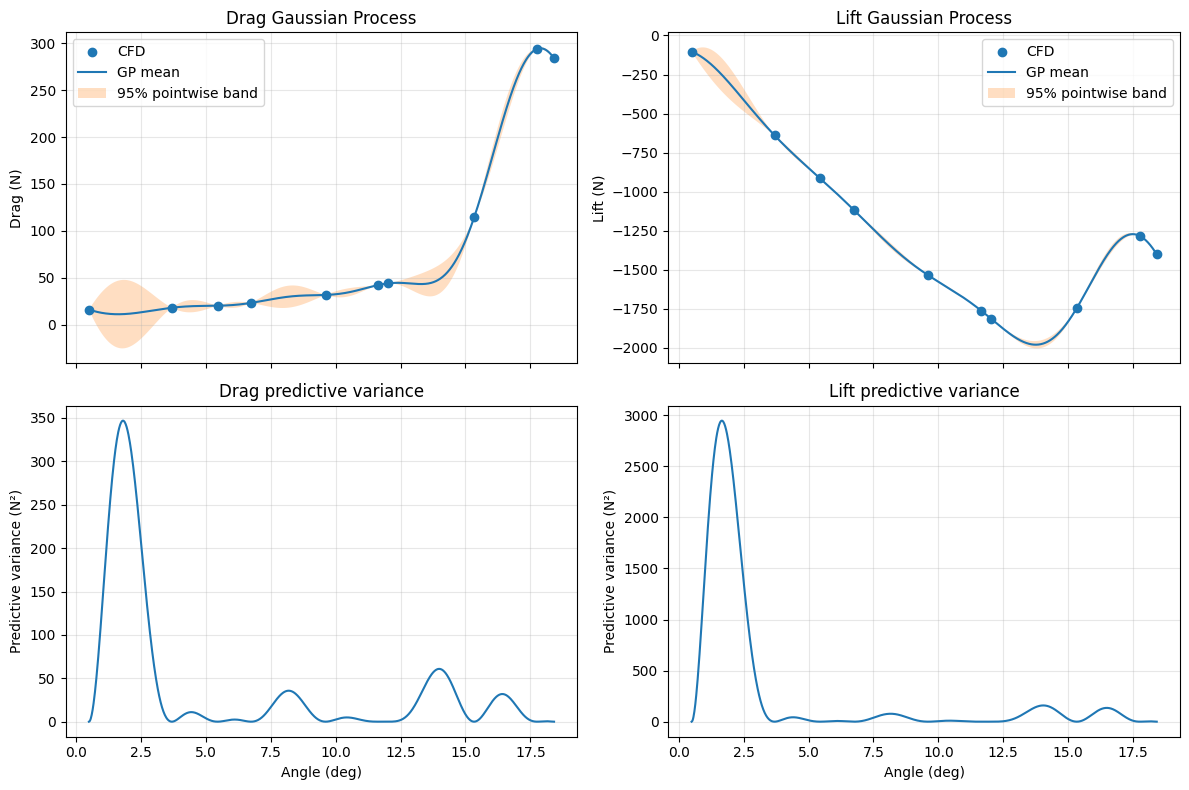

Highest drag variance: 346.875 N² at 1.801 deg
Highest lift variance: 2947.276 N² at 1.658 deg


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex="col")

axes[0, 0].scatter(df.angle_deg, df.drag_N, label="CFD", zorder=3)
axes[0, 0].plot(angle_grid, drag_mean, label="GP mean")
axes[0, 0].fill_between(
    angle_grid,
    drag_mean - 1.96 * drag_std,
    drag_mean + 1.96 * drag_std,
    alpha=0.25,
    label="95% pointwise band",
)
axes[0, 0].set_ylabel("Drag (N)")
axes[0, 0].set_title("Drag Gaussian Process")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].scatter(df.angle_deg, df.lift_N, label="CFD", zorder=3)
axes[0, 1].plot(angle_grid, lift_mean, label="GP mean")
axes[0, 1].fill_between(
    angle_grid,
    lift_mean - 1.96 * lift_std,
    lift_mean + 1.96 * lift_std,
    alpha=0.25,
    label="95% pointwise band",
)
axes[0, 1].set_ylabel("Lift (N)")
axes[0, 1].set_title("Lift Gaussian Process")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(angle_grid, drag_var)
axes[1, 0].set_xlabel("Angle (deg)")
axes[1, 0].set_ylabel("Predictive variance (N²)")
axes[1, 0].set_title("Drag predictive variance")
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(angle_grid, lift_var)
axes[1, 1].set_xlabel("Angle (deg)")
axes[1, 1].set_ylabel("Predictive variance (N²)")
axes[1, 1].set_title("Lift predictive variance")
axes[1, 1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

id_drag_var = int(np.argmax(drag_var))
id_lift_var = int(np.argmax(lift_var))

print(
    "Highest drag variance: {:.3f} N² at {:.3f} deg".format(
        drag_var[id_drag_var], angle_grid[id_drag_var]
    )
)
print(
    "Highest lift variance: {:.3f} N² at {:.3f} deg".format(
        lift_var[id_lift_var], angle_grid[id_lift_var]
    )
)

The plotted GP variance is **surrogate-model uncertainty due to sparse sample locations and the fitted covariance structure**. It is not the same thing as CFD numerical uncertainty.

Mesh density, incomplete iterative convergence, turbulence-model limitations, and potentially unsteady separated flow can change the CFD force values themselves. A GP fitted to those values will learn that shifted response. GP predictive uncertainty and CFD numerical/model-form uncertainty should therefore be assessed separately.

## Task III – Engineering Recommendation

### Step 17 – Predicted drag-to-downforce ratio

For every grid angle, compute:

\[
rac{\hat D(lpha)}{-\hat L(lpha)}
\]

and apply the same 500 N minimum predicted downforce. The eligible grid point with the lowest predicted ratio is compared with the best actually sampled CFD point.

In [8]:
pred_downforce = -lift_mean
pred_ratio = np.where(
    pred_downforce >= MIN_DOWNFORCE_N,
    drag_mean / pred_downforce,
    np.nan,
)

best_i = int(np.nanargmin(pred_ratio))
best_angle = float(angle_grid[best_i])
best_drag = float(drag_mean[best_i])
best_lift = float(lift_mean[best_i])
best_downforce = float(pred_downforce[best_i])
best_ratio = float(pred_ratio[best_i])

boundary = (
    np.isclose(best_angle, angle_grid.min())
    or np.isclose(best_angle, angle_grid.max())
)

observed_eligible = df[df.downforce_N >= MIN_DOWNFORCE_N].copy()
obs_i = observed_eligible.drag_to_downforce.idxmin()
obs_best = df.loc[obs_i]

print(f"Best eligible GP angle: {best_angle:.3f} deg")
print(f"Predicted drag: {best_drag:.3f} N")
print(f"Predicted lift: {best_lift:.3f} N")
print(f"Predicted downforce: {best_downforce:.3f} N")
print(f"Predicted D/downforce: {best_ratio:.6f}")
print("At sampled-range boundary:", bool(boundary))
print()
print(f"Best sampled angle: {obs_best.angle_deg:.3f} deg")
print(f"Observed drag: {obs_best.drag_N:.3f} N")
print(f"Observed downforce: {obs_best.downforce_N:.3f} N")
print(f"Observed D/downforce: {obs_best.drag_to_downforce:.6f}")

Best eligible GP angle: 9.874 deg
Predicted drag: 32.088 N
Predicted lift: -1563.666 N
Predicted downforce: 1563.666 N
Predicted D/downforce: 0.020521
At sampled-range boundary: False

Best sampled angle: 9.613 deg
Observed drag: 31.665 N
Observed downforce: 1535.787 N
Observed D/downforce: 0.020618


In [9]:
candidate_X = np.array([[best_angle]])
_, cand_drag_std = gp_drag_final.predict(candidate_X, return_std=True)
_, cand_lift_std = gp_lift_final.predict(candidate_X, return_std=True)

print(f"Candidate drag variance: {cand_drag_std[0]**2:.3f} N²")
print(f"Candidate lift variance: {cand_lift_std[0]**2:.3f} N²")
print(
    "Approx. 95% drag interval: [{:.3f}, {:.3f}] N".format(
        best_drag - 1.96 * cand_drag_std[0],
        best_drag + 1.96 * cand_drag_std[0],
    )
)
print(
    "Approx. 95% lift interval: [{:.3f}, {:.3f}] N".format(
        best_lift - 1.96 * cand_lift_std[0],
        best_lift + 1.96 * cand_lift_std[0],
    )
)

Candidate drag variance: 1.351 N²
Candidate lift variance: 2.708 N²
Approx. 95% drag interval: [29.809, 34.366] N
Approx. 95% lift interval: [-1566.892, -1560.440] N


### Steps 18–19 – Recommended follow-up Fluent simulation

I recommend a **9.87°** follow-up Fluent simulation.

The final GP predicts approximately **32.09 N drag** and **1563.67 N downforce**, giving a drag-to-downforce ratio of about **0.020521**. The point lies inside the simulated range rather than at a boundary, and it is very close to the best sampled case at **9.61°**, which produced about **31.67 N drag**, **1535.79 N downforce**, and an observed ratio of about **0.020618**.

The held-out tests show that the largest drag and lift errors occur at **17.76°**, so the high-angle region should be treated more cautiously. In contrast, predictive variance near the proposed 9.87° candidate is small: about **1.35 N² for drag** and **2.71 N² for lift**. This supports choosing a verification case in the mid-angle efficiency region rather than chasing a high-angle surrogate feature.

A favorable ratio alone is not enough to choose a rear-wing setting because it does not state how much absolute downforce is available. The 500 N minimum-load screen prevents a low-load point from being selected simply because its ratio looks favorable.

#### Verification plan

Run one new Fluent case at **9.87°** using the same geometry, mesh strategy, 50 m/s inlet, boundary conditions, solver/turbulence settings, convergence criteria, and force-report definitions as the sweep. After convergence:

1. compare measured drag and lift with the GP predictive means and their pointwise uncertainty intervals,
2. compute downforce as `-lift`,
3. compute the measured drag/downforce ratio,
4. compare the new result with both the GP prediction and the measured 9.61° case,
5. if the verification result falls well outside the GP bands, inspect convergence, mesh sensitivity, and separated/unsteady-flow behavior before trusting the surrogate locally.

#### 2D-model limitation

This is a **2D airfoil-section study**, not a complete race-car rear wing. It does not capture finite-span effects, tip vortices, endplates, body/wing interaction, ground interaction, yaw, or nonuniform inflow. Therefore, the recommended angle is a follow-up CFD candidate rather than a final vehicle setup decision.
